# Models: Logistic and Gompertz

This notebook is the model part of this FinalProject, We consider this two tumor growth models: Logistic model and Gompertz model.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Equations and parameters

### 1.1 A growth model is an equation for the rate of change

$V(t)$ is the tumor volume at time $t$. Both models are initial value problems: given the growth rate and the starting volume,and find the curve $V(t)$.

$$\frac{dV}{dt} = f(t, V), \qquad V(0) = V_0$$


The two models differ only in the right-hand side $f(t, V)$.

### 1.2 Logistic model

The logistic model is defined by

$$\frac{dV}{dt} = a_L \, V \left(1 - \frac{V}{K}\right)$$

| Parameter | Meaning |
|---|---|
| $a_L$ | Relative growth rate of a small tumor . For $V \ll K$ the bracket is close to 1 and the equation is close to $dV/dt = a_L V$ |
| $K$ | Carrying capacity, the upper bound of the volume. As $V \to K$ the bracket goes to 0 and growth stops |

The closer $V$ is to $K$, the slower the growth.

### 1.3 Gompertz model

$$\frac{dV}{dt} = a_G \, e^{-\beta t} \, V$$

| Parameter | Meaning |
|---|---|
| $a_G$ | Relative growth rate at $t = 0$  |
| $\beta$ | Decay rate of the growth rate . The relative growth rate $a_G e^{-\beta t}$ decays exponentially in time |

The growth rate decays to 0, and the volume levels off at a plateau
$K_G = V_0 \, e^{a_G/\beta}$(derived in 3.1).


### 1.4 Autonomous and non-autonomous

- **Autonomous**: $f$ does not contain $t$ explicitly and depends only on $V$. The Logistic model is autonomous.
- **Non-autonomous**: $f$ contains $t$ explicitly. The Gompertz model is non-autonomous.

This matters for the numerical methods. Some methods do not evaluate $f$ at the start of a step. Backward Euler uses the time at the end of the step.
For Gompertz the time at which $f$ is evaluated changes the result; for Logistic it does not.

So every model function takes `t` as an argument, even when the Logistic model does not use it, and the solvers can call both models in the same way.

### 1.5 What the code needs from each model

The project plan is to solve the equation with numerical methods and measure their errors. For that, each model has to provide:

1. **`rhs`**: the right-hand side $f(t, V)$. Every numerical method needs it.
2. **`exact`**: the exact solution $V(t)$. With it we can measure the error of a numerical method directly: error = computed minus exact.
   These two models have exact solution, which is why we can use them to test methods.
3. **`be_step`**: one step of the Backward Euler method. That method needs to solve an equation at every step; for these two models we can solve it by hand.
4. **`dfdV`**: $\partial f / \partial V$, needed later for the stability analysis.

### 1.6 Dictioaries to store Parameters
Each model has its own parameters: the Logistic model has $a_L$ and $K$, the Gompertz model has $a_G$ and $\beta$.
We want every model's functions to be called in the same way,
for example `rhs(t, V, p)`, no matter which model.

So we put the parameters of one model into one dictionary `p`, for example `p_L = {"a_L": 0.2222, "K": 10}`. A function then gets a value with `p["K"]`.


## 2. Logistic: right-hand side and exact solution

### 2.0 Example Parameter
We choose $V_0 = 1$, $K = 10$, and look at the time interval $[0, T]$ with $T = 60$.

For $a_L$ we use the relative growth rate $\frac{1}{V}\frac{dV}{dt}$.

Dividing the equation by $V$ gives

$$\frac{1}{V}\frac{dV}{dt} = a_L\left(1 - \frac{V}{K}\right)$$

At the start, $V = V_0 = 1$, so the relative growth rate is $a_L(1 - 1/10) = 0.9\, a_L$.
We want it to be $0.2$ (20% per unit time), so

$$0.9\, a_L = 0.2 \quad\Longrightarrow\quad a_L = \frac{0.2}{0.9} = 0.2222\ldots$$

In [2]:
V0 = 1.0
T = 60.0
plateau = 10.0

a_L = 0.2 / (1 - V0 / plateau)
p_L = {"a_L": a_L, "K": plateau}

print("p_L =", p_L)
print("initial relative growth rate =", p_L["a_L"] * (1 - V0 / p_L["K"]))

p_L = {'a_L': 0.22222222222222224, 'K': 10.0}
initial relative growth rate = 0.2


### 2.1 Right-hand side

$$f(t, V) = a_L \, V \left(1 - \frac{V}{K}\right)$$


In [3]:
def logistic_rhs(t, V, p):
    a_L = p["a_L"]
    K = p["K"]
    return a_L * V * (1 - V / K)

### 2.2 Exact solution (`logistic_exact`)
We assume $0 < V_0 < K$. Then $V(t)$ stays between $0$ and $K$, so we may divide by $V$ and by $K - V$.

**1: separate the variables.** Dividing by $V\left(1 - \frac{V}{K}\right) = \frac{V(K - V)}{K}$ gives

$$\frac{K}{V(K - V)}\,\frac{dV}{dt} = a_L, \qquad \text{and} \qquad \frac{K}{V(K - V)} = \frac{1}{V} + \frac{1}{K - V}$$


**2: integrate from $0$ to $t$.** An antiderivative of $\frac{1}{V} + \frac{1}{K - V}$ is $\ln V - \ln(K - V) = \ln\frac{V}{K - V}$, so

$$\ln\frac{V}{K - V} - \ln\frac{V_0}{K - V_0} = a_L\, t
\quad\Longrightarrow\quad
\frac{V}{K - V} = \frac{V_0}{K - V_0}\, e^{a_L t}$$

**3: solve for $V$.** Write $r = \frac{V_0}{K - V_0}$ for short. Multiply by $K - V$ and collect the $V$ terms on the left:

$$V\left(1 + r e^{a_L t}\right) = K r e^{a_L t}
\quad\Longrightarrow\quad
V = \frac{K r e^{a_L t}}{1 + r e^{a_L t}} = \frac{K}{1 + \frac{1}{r} e^{-a_L t}}$$

With $\frac{1}{r} = \frac{K}{V_0} - 1$:

$$V(t) = \frac{K}{1 + \left(\dfrac{K}{V_0} - 1\right) e^{-a_L t}}$$


**Other starting values.** For $V_0 > K$ the same steps (with $\ln\lvert K - V\rvert$) give the same formula, and the curve decreases toward $K$.
For $V_0 = K$ the formula gives the constant $K$. $V_0 = 0$ would divide by zero, so we never use it.

In [4]:
def logistic_exact(t, V0, p):
    a_L = p["a_L"]
    K = p["K"]
    return K / (1 + (K / V0 - 1) * np.exp(-a_L * t))


print("V(10) =", logistic_exact(10.0, V0, p_L))
print("V at t = 0, 10, 20, 60:", logistic_exact(np.array([0.0, 10.0, 20.0, 60.0]), V0, p_L))

V(10) = 5.0624908581298955
V at t = 0, 10, 20, 60: [1.         5.06249086 9.04410457 9.99985424]


### 2.3 Check the exact solution equals $V_0$ at $t = 0$

In [5]:
V_at_0 = logistic_exact(0.0, V0, p_L)
print("exact(0) =", V_at_0, "   V0 =", V0)

exact(0) = 1.0    V0 = 1.0


### 2.4 Picture of Logistic curve

Two starting volumes: $V_0 = 1$ (below $K$, the S-shaped growth curve) and $V_0 = 20$ (above $K$, decreases toward $K$).

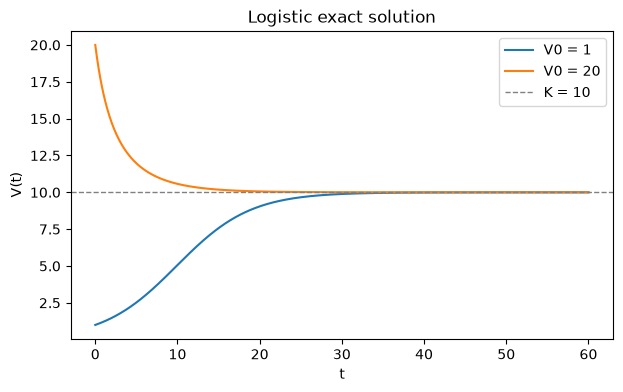

In [6]:
t_plot = np.linspace(0, T, 601)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t_plot, logistic_exact(t_plot, 1.0, p_L), label="V0 = 1")
ax.plot(t_plot, logistic_exact(t_plot, 20.0, p_L), label="V0 = 20")
ax.axhline(p_L["K"], color="gray", linestyle="--", linewidth=1, label="K = 10")
ax.set_xlabel("t")
ax.set_ylabel("V(t)")
ax.set_title("Logistic exact solution")
ax.legend()
plt.show()

## 3. Gompertz: right-hand side and exact solution

### 3.1 Exact solution

We assume $V > 0$, so that we may divide by $V$.

**1: separate the variables.** Divide by $V$:

$$\frac{1}{V}\,\frac{dV}{dt} = a_G\, e^{-\beta t}$$

**2: integrate from $0$ to $t$.** The left side is $\frac{d}{dt}\ln V(t)$ (chain rule), and $\int_0^t e^{-\beta s}\, ds = \frac{1}{\beta}\left(1 - e^{-\beta t}\right)$, so

$$\ln V(t) - \ln V_0 = \frac{a_G}{\beta}\left(1 - e^{-\beta t}\right)$$

**3: remove the logarithm.**

$$V(t) = V_0 \exp\!\left[\frac{a_G}{\beta}\left(1 - e^{-\beta t}\right)\right]$$

As $t \to \infty$, $e^{-\beta t} \to 0$, so $V \to V_0 e^{a_G/\beta}$. This is the plateau $K_G$.

Note: the Gompertz parameters do not contain upper bound like $K$. The plateau is decided by $V_0$, $a_G$ and $\beta$; a different $V_0$ gives a different plateau.



### 3.2 Example parameter values

- $a_G = 0.2$: the same initial relative growth rate as our Logistic example.
- $\beta$: chosen so that the plateau also equals $10$, like the Logistic K.

Solve $V_0 e^{a_G/\beta} = 10$: divide by $V_0$, take $\ln$: 

$\frac{a_G}{\beta} = \ln\frac{10}{V_0}$,

so

$$\beta = \frac{a_G}{\ln(10 / V_0)} = 0.08686$$

In [7]:
a_G = 0.2
beta = a_G / np.log(plateau / V0)
p_G = {"a_G": a_G, "beta": beta}
print("p_G =", p_G)

p_G = {'a_G': 0.2, 'beta': np.float64(0.08685889638065036)}


### 3.3 Code of  `gompertz_rhs` and `gompertz_exact` 

In [8]:
def gompertz_rhs(t, V, p):
    a_G = p["a_G"]
    beta = p["beta"]
    return a_G * np.exp(-beta * t) * V


def gompertz_exact(t, V0, p):
    a_G = p["a_G"]
    beta = p["beta"]
    return V0 * np.exp(a_G / beta * (1 - np.exp(-beta * t)))

print("rate at t = 0,  V = 1:", gompertz_rhs(0.0, 1.0, p_G))
print("rate at t = 20, V = 1:", gompertz_rhs(20.0, 1.0, p_G))
print("V at t = 0, 10, 20, 60:", gompertz_exact(np.array([0.0, 10.0, 20.0, 60.0]), V0, p_G))

rate at t = 0,  V = 1: 0.2
rate at t = 20, V = 1: 0.03520328629624632
V at t = 0, 10, 20, 60: [1.         3.80589566 6.66781541 9.87521812]


### 3.4 Check that the exact solution equals $V_0$ at $t = 0$

In [9]:
V_at_0 = gompertz_exact(0.0, V0, p_G)
print("exact(0) =", V_at_0, "   V0 =", V0)

exact(0) = 1.0    V0 = 1.0


### 3.5 Check that the solution approaches the plateau $K_G$
Compute $K_G = V_0 e^{a_G/\beta}$ from the formula and compare with the exact solution at a very large time $t = 1000$, where $e^{-\beta t}$ small enough.


In [10]:
K_G = V0 * np.exp(p_G["a_G"] / p_G["beta"])
V_large_t = gompertz_exact(1000.0, V0, p_G)

print("K_G         =", K_G)
print("exact(1000) =", V_large_t)

K_G         = 10.000000000000002
exact(1000) = 10.000000000000002


## 4 Time stepping: Forward Euler and Backward Euler

### 4.1 The time grid

Choose a **step size** $h > 0$. The method computes the volume at the grid times

$$t_n = n\, h, \qquad n = 0, 1, 2, \ldots$$

and $V_n$ denotes the computed approximation of $V(t_n)$. We start with $V_0$ and go from $V_n$ to $V_{n+1}$ one step at a time.


### 4.2 Forward Euler
we use the slope at the current point, $f(t_n, V_n)$:

$$V_{n+1} = V_n + h\, f(t_n, V_n)$$

Everything on the right is known, so this is explict

### 4.3 Backward Euler 

Use the slope at the next point instead:

$$V_{n+1} = V_n + h\, f(t_{n+1}, V_{n+1})$$

Now the unknown $V_{n+1}$ appears on **both** sides. Each step is an equation that has to be solved for $V_{n+1}$. (implicit)<br>


In general such an equation is solved approximately with an iterative method (for example Newton's method). 

But for our two models, we can solve it by hand and get a closed formula. That formula is the function `be_step`:

**input:**
the next time $t_{n+1}$ (`t_next`),the current volume $V_n$ (`V_prev`), the step size `h`, the parameters `p`

**output:**
$V_{n+1}$ (`V_next`)


The argument order is `be_step(t_next, V_prev, h, p)` for both models, for the same reason as before: a solver can call any model's `be_step` the same way.

## 5 The Backward Euler step for the Logistic model

### 5.1 The implicit equation is a quadratic

Put $f(t, V) = a_L V \left(1 - \frac{V}{K}\right)$ into the Backward Euler equation $V_{n+1} = V_n + h\, f(t_{n+1}, V_{n+1})$:

$$V_{next} = V_{prev} + h\, a_L V_{next}\left(1 - \frac{V_{next}}{K}\right)$$

Multiply out the bracket and move everything to the left side gives a quadratic equation for $V_{next}$:

$$c\, V_{next}^2 + B\, V_{next} - V_{prev} = 0, \qquad c = \frac{h a_L}{K}, \quad B = 1 - h a_L \tag{Q}$$

### 5.2 Root

The roots of (Q) are

$$x_\pm = \frac{-B \pm \sqrt{D}}{2c}, \qquad D = B^2 + 4 c V_{prev}$$

The product of the two roots is $-V_{prev}/c$, which is negative because $c > 0$ and $V_{prev} > 0$. So one root is positive and the other is negative.
The volume must be positive, so we take the positive root:

$$V_{next} = \frac{-B + \sqrt{D}}{2c}$$


### 5.3 Code: `logistic_be_step`


In [11]:
def logistic_be_step(t_next, V_prev, h, p):
    a_L = p["a_L"]
    K = p["K"]
    c = h * a_L / K
    B = 1 - h * a_L
    D = B**2 + 4 * c * V_prev
    return (-B + np.sqrt(D)) / (2 * c)


print("BE step, h = 1, V_prev = 1:", logistic_be_step(1.0, 1.0, 1.0, p_L))

BE step, h = 1, V_prev = 1: 1.241664813991312


### 5.4 Check: put the result back into the equation

The Backward Euler equation is $V_{next} = V_{prev} + h\, f(t_{next}, V_{next})$.
So we compute $V_{next}$ with `logistic_be_step`, put it into the right side of the equation, and look whether the same number comes back.
We start from $V_{prev} = 1$ and try a small, a medium and a large step.

In [12]:
V_prev = 1.0
for h in [0.1, 1.0, 10.0]:
    V_next = logistic_be_step(h, V_prev, h, p_L)
    right_side = V_prev + h * logistic_rhs(h, V_next, p_L)
    print("h =", h, "  V_next =", round(V_next, 6), "  right side =", round(right_side, 6))

h = 0.1   V_next = 1.020361   right side = 1.020361
h = 1.0   V_next = 1.241665   right side = 1.241665
h = 10.0   V_next = 6.223111   right side = 6.223111


### 5.5 Check: one step compared with the exact solution

One step with $h = 1$ from $V_0 = 1$, next to the Forward Euler step and the exact value $V(1)$.

In [13]:
h = 1.0
print("Forward Euler step :", V0 + h * logistic_rhs(0.0, V0, p_L))
print("exact V(1)         :", logistic_exact(1.0, V0, p_L))
print("Backward Euler step:", logistic_be_step(1.0, V0, h, p_L))

Forward Euler step : 1.2
exact V(1)         : 1.2185259876149679
Backward Euler step: 1.241664813991312


## 6 The Backward Euler step for the Gompertz model

### 6.1 The implicit equation is linear

Insert $f(t, V) = a_G e^{-\beta t} V$ into the Backward Euler equation $V_{n+1} = V_n + h\, f(t_{n+1}, V_{n+1})$. The rate is taken at the next point, so the time is $t_{next}$:

$$V_{next} = V_{prev} + h\, a_G e^{-\beta t_{next}}\, V_{next}$$

Write $\lambda = a_G e^{-\beta t_{next}}$ . The equation $V_{next} = V_{prev} + h\lambda V_{next}$ is linear in $V_{next}$:

$V_{next}(1 - h\lambda) = V_{prev}$, 

so, if $1 - h\lambda \ne 0$,

$$V_{next} = \frac{V_{prev}}{1 - h\, a_G e^{-\beta t_{next}}}$$

### 6.2 When the step fails

if the denominator is $\le 0$, `be_step` returns `np.nan`  instead of a wrong volume.

### 6.3 Code of `gompertz_be_step`

In [14]:
def gompertz_be_step(t_next, V_prev, h, p):
    a_G = p["a_G"]
    beta = p["beta"]
    denom = 1 - h * a_G * np.exp(-beta * t_next)
    if denom <= 0:
        return np.nan
    return V_prev / denom


print("BE step, h = 1, t_next = 1, V_prev = 1 :", gompertz_be_step(1.0, 1.0, 1.0, p_G))
print("BE step, h = 10, t_next = 0, V_prev = 1:", gompertz_be_step(0.0, 1.0, 10.0, p_G))

BE step, h = 1, t_next = 1, V_prev = 1 : 1.2245317152521518
BE step, h = 10, t_next = 0, V_prev = 1: nan


### 6.4 Check: put the result back into the equation

The same check as for the Logistic step: compute $V_{next}$, put it into the right side $V_{prev} + h\, f(t_{next}, V_{next})$, and compare.
use $h = 1$, $V_{prev} = 2$ and three different times $t_{next}$, because the Gompertz rate depends on time.

In [15]:
V_prev = 2.0
h = 1.0
for t_next in [1.0, 10.0, 30.0]:
    V_next = gompertz_be_step(t_next, V_prev, h, p_G)
    right_side = V_prev + h * gompertz_rhs(t_next, V_next, p_G)
    print("t_next =", t_next, "  V_next =", round(V_next, 6), "  right side =", round(right_side, 6))

t_next = 1.0   V_next = 2.449063   right side = 2.449063
t_next = 10.0   V_next = 2.183188   right side = 2.183188
t_next = 30.0   V_next = 2.029981   right side = 2.029981


## 7. The derivative $\partial f / \partial V$ (`dfdV`)

$\lambda = \partial f / \partial V$ is the change of the rate $f$ per unit change of $V$, at fixed $t$. It will appear in furthur analasys.

### 7.1 Logistic

$f = a_L V - \frac{a_L}{K} V^2$, so

$$\frac{\partial f}{\partial V} = a_L\left(1 - \frac{2V}{K}\right)$$

Note: 
$\lambda = a_L$ at $V = 0$, 
$\lambda = 0$ at $V = K/2$, and
$\lambda = -a_L$ at $V = K$.



### 7.2 Gompertz

$f = a_G e^{-\beta t}\, V$ is $V$ times a factor that does not depend on $V$, so

$$\frac{\partial f}{\partial V} = a_G e^{-\beta t}$$

It does not depend on $V$, and always positive, and decays to $0$ in time.
Note that the denominator of the Gompertz Backward Euler step is exactly $1 - h\,\frac{\partial f}{\partial V}(t_{next})$, so the step fails when $h\,\frac{\partial f}{\partial V} \ge 1$.

### 7.3 Code

In [16]:
def logistic_dfdV(t, V, p):
    a_L = p["a_L"]
    K = p["K"]
    return a_L * (1 - 2 * V / K)


def gompertz_dfdV(t, V, p):
    a_G = p["a_G"]
    beta = p["beta"]
    return a_G * np.exp(-beta * t)

### 7.5 Check the values we can predict

For the Logistic model we know the three special points from above: 

$a_L$ at $V = 0$,

$0$ at $V = K/2$,

$-a_L$ at $V = K$.

For the Gompertz model the value at $t = 0$ must be $a_G = 0.2$, and a later value must be smaller.

In [17]:
K = p_L["K"]
print("a_L =", p_L["a_L"])
print("logistic dfdV at V = 0   :", logistic_dfdV(0.0, 0.0, p_L))
print("logistic dfdV at V = K/2 :", logistic_dfdV(0.0, K / 2, p_L))
print("logistic dfdV at V = K   :", logistic_dfdV(0.0, K, p_L))

print("gompertz dfdV at t = 0   :", gompertz_dfdV(0.0, 1.0, p_G))
print("gompertz dfdV at t = 20  :", gompertz_dfdV(20.0, 1.0, p_G))

a_L = 0.22222222222222224
logistic dfdV at V = 0   : 0.22222222222222224
logistic dfdV at V = K/2 : 0.0
logistic dfdV at V = K   : -0.22222222222222224
gompertz dfdV at t = 0   : 0.2
gompertz dfdV at t = 20  : 0.03520328629624632


## 8. The `MODELS` dictionary: structured for all models

### 8.1 Idea

Later we need to run the same numerical method on both models, and don't want to write the code twice.
For that, both models should be used in the same way.

That is why every model has the same four functions, `rhs`, `exact`, `be_step`, `dfdV`, and they take the same arguments.
We put them into one dictionary: `MODELS["logistic"]["rhs"]` is `logistic_rhs`, `MODELS["gompertz"]["rhs"]` is `gompertz_rhs`, and so on.
A method then only needs to be told the model name.


 ### 8.2 Code

In [18]:
MODELS = {
    "logistic": {
        "rhs": logistic_rhs,
        "exact": logistic_exact,
        "be_step": logistic_be_step,
        "dfdV": logistic_dfdV,
    },
    "gompertz": {
        "rhs": gompertz_rhs,
        "exact": gompertz_exact,
        "be_step": gompertz_be_step,
        "dfdV": gompertz_dfdV,
    },
}

### 8.3 Check: both models have the same four keys

In [19]:
for model_name, model in MODELS.items():
    print(model_name, "->", list(model.keys()))

logistic -> ['rhs', 'exact', 'be_step', 'dfdV']
gompertz -> ['rhs', 'exact', 'be_step', 'dfdV']


### 8.4 Picture: both exact solutions, drawn through `MODELS`

We draw both curves with one loop over `MODELS`. With the example parameters both curves start at $V_0 = 1$ with relative growth rate $0.2$ and level off at $10$;
the Logistic curve gets there faster.

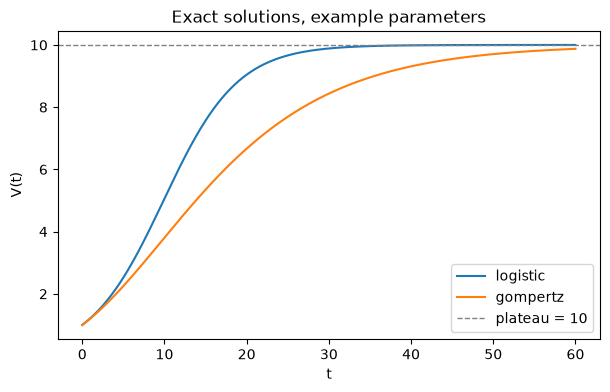

In [20]:
params = {"logistic": p_L, "gompertz": p_G}
t_plot = np.linspace(0, T, 601)

fig, ax = plt.subplots(figsize=(7, 4))
for model_name, model in MODELS.items():
    ax.plot(t_plot, model["exact"](t_plot, V0, params[model_name]), label=model_name)

ax.axhline(plateau, color="gray", linestyle="--", linewidth=1, label="plateau = 10")
ax.set_xlabel("t")
ax.set_ylabel("V(t)")
ax.set_title("Exact solutions, example parameters")
ax.legend()
plt.show()

## AI Use Declaration

I used Claude in the following ways while preparing this notebook:

- **Plotting**: The matplotlib code for the figures was written with AI assistance. I checked that the plots match the exact solutions.
- [**Code structure**: The idea of storing model functions in a `MODELS` dictionary with a common signature came from a discussion with AI.]
- [**Review**: I used AI to review the notebook for errors and unclear explanations.]

